# Food Delivery: Vendors, Segments, and a Misleading Regression

A food delivery app works in eight markets. Three questions from its marketing team:

1. Do a few vendors take most of the orders in each market?
2. Can vendors be grouped into segments that marketing could treat differently?
3. A regression found that a voucher on a customer's first visit adds 5+ orders over their lifetime. Can that number be trusted?

**Data:** synthetic, generated by [make_data.py](make_data.py).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
orders = pd.read_csv("orders.csv.gz")
print(f"{len(orders):,} orders from {orders.groupby(['market', 'vendor']).ngroups:,} vendors in {orders.market.nunique()} markets")
orders.head()

116,000 orders from 5,363 vendors in 8 markets


,order_id,market,vendor,cuisine,customer_id,basket_eur,delivery_fee_eur,is_discount,is_voucher
0,1,UAE,UAE-0833,shawarma,UA005768,8.21,0.37,False,False
1,2,UAE,UAE-1322,shawarma,UA008998,21.08,1.84,False,False
2,3,UAE,UAE-0799,pizza,UA000489,12.22,0.87,False,False
3,4,UAE,UAE-0989,coffee,UA003387,10.06,0.89,False,False
4,5,UAE,UAE-1323,chicken,UA008804,10.18,1.34,False,False


In [3]:
orders.groupby("market").agg(orders=("order_id", "size"), vendors=("vendor", "nunique"),
                             average_basket_eur=("basket_eur", "mean")).sort_values("orders", ascending=False).round(1)

,orders,vendors,average_basket_eur
market,,,
Kuwait,34000,1191,15.4
UAE,30000,1358,16.6
Egypt,15000,850,16.1
Qatar,13000,587,14.1
Bahrain,12000,630,14.5
Oman,8000,422,15.0
Jordan,2500,228,16.6
Saudi Arabia,1500,97,25.2


## 1. Are orders concentrated in a few vendors?

Two measures per market: the share of orders taken by the top 5 vendors, and the **Herfindahl-Hirschman Index** (HHI), the sum of every vendor's squared market share × 10,000. It ranges from near 0 (many small vendors) to 10,000 (one vendor takes everything); competition authorities treat a market under 1,500 as unconcentrated and over 2,500 as highly concentrated.

In [4]:
counts = orders.groupby(["market", "vendor"]).size()
share = counts / counts.groupby(level="market").transform("sum")
concentration = pd.DataFrame({
    "vendors": counts.groupby(level="market").size(),
    "top 5 share": share.groupby(level="market").apply(lambda s: s.nlargest(5).sum()),
    "HHI": (share ** 2).groupby(level="market").sum() * 10_000,
}).sort_values("HHI", ascending=False)
concentration.round({"top 5 share": 2, "HHI": 0})

,vendors,top 5 share,HHI
market,,,
Saudi Arabia,97,0.63,1070.0
Oman,422,0.35,365.0
Jordan,228,0.29,249.0
Qatar,587,0.20,137.0
Egypt,850,0.20,129.0
Bahrain,630,0.14,95.0
UAE,1358,0.13,63.0
Kuwait,1191,0.11,52.0


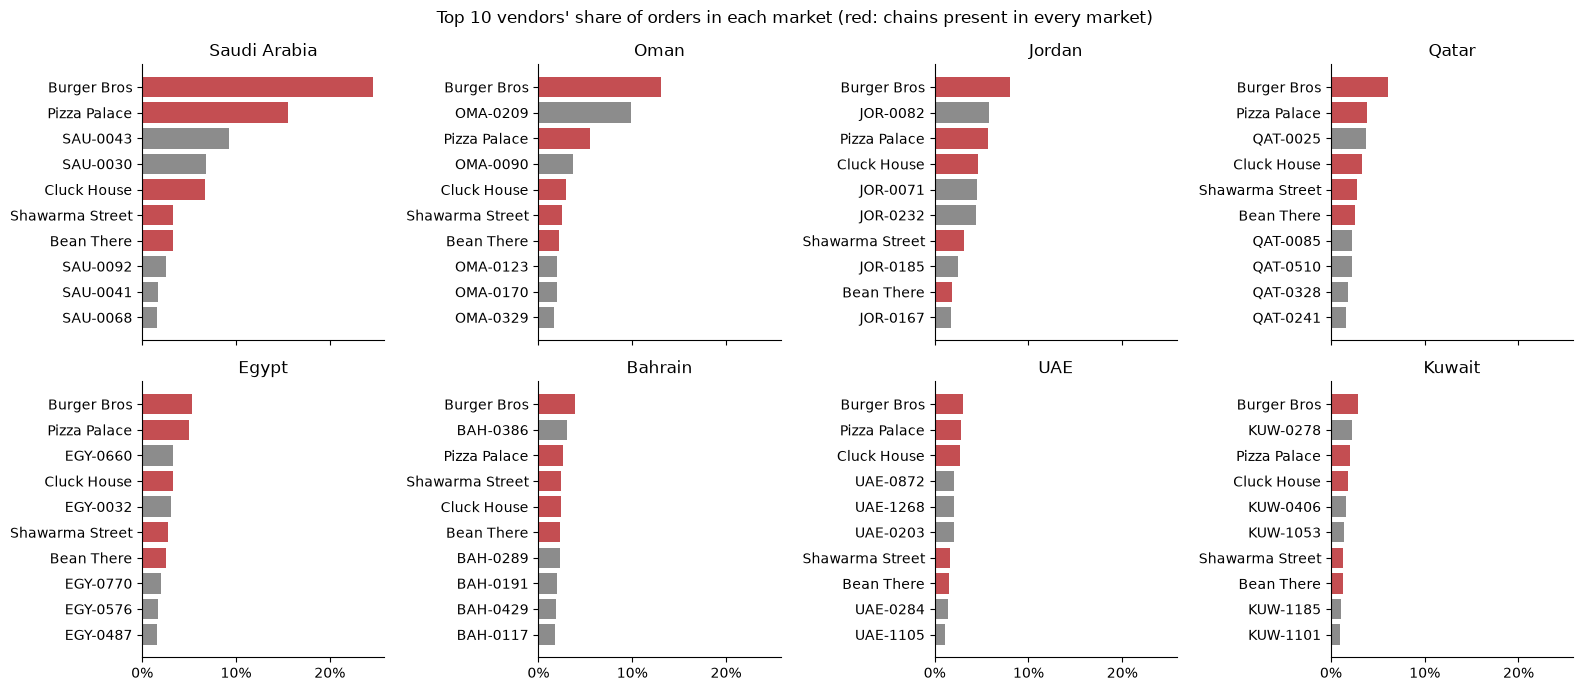

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
for ax, market in zip(axes.flat, concentration.index):
    top = share[market].nlargest(10)[::-1]
    ax.barh(top.index, top.values, color=["#c44e52" if not v.startswith(market[:3].upper()) else "#8c8c8c" for v in top.index])
    ax.set_title(market)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
fig.suptitle("Top 10 vendors' share of orders in each market (red: chains present in every market)")
plt.tight_layout()
plt.show()

## 2. Vendor segments

Each vendor in each market is described by five numbers: how many orders it gets, the average basket, the average delivery fee, and how often its orders use a discount or a voucher. Order counts are very skewed, so they are log-transformed; all five are then put on the same scale, and k-means groups similar vendors. The number of segments is picked by the silhouette score (how clearly the groups separate).

In [6]:
vendors = orders.groupby(["market", "vendor"]).agg(
    orders=("order_id", "size"), basket=("basket_eur", "mean"), delivery_fee=("delivery_fee_eur", "mean"),
    discount_share=("is_discount", "mean"), voucher_share=("is_voucher", "mean")).reset_index()
vendors = vendors[vendors.orders >= 5]          # too few orders to describe a vendor reliably
X = StandardScaler().fit_transform(vendors[["orders", "basket", "delivery_fee", "discount_share", "voucher_share"]]
                                   .assign(orders=np.log(vendors.orders)))
scores = {k: silhouette_score(X, KMeans(k, n_init=10, random_state=0).fit_predict(X), sample_size=3000, random_state=0)
          for k in range(2, 8)}
print({k: round(v, 3) for k, v in scores.items()})

{2: 0.241, 3: 0.21, 4: 0.209, 5: 0.19, 6: 0.196, 7: 0.2}


In [7]:
K = 4
vendors["segment"] = KMeans(K, n_init=10, random_state=0).fit_predict(X)
profile = vendors.groupby("segment").agg(vendors=("vendor", "size"), median_orders=("orders", "median"),
                                         basket=("basket", "mean"), delivery_fee=("delivery_fee", "mean"),
                                         discount_share=("discount_share", "mean"), voucher_share=("voucher_share", "mean"))
profile["share of all orders"] = vendors.groupby("segment").orders.sum() / vendors.orders.sum()
profile.round(2)

,vendors,median_orders,basket,delivery_fee,discount_share,voucher_share,share of all orders
segment,,,,,,,
0,622,12.0,28.38,1.10,0.11,0.02,0.10
1,719,55.0,13.65,1.08,0.15,0.04,0.64
2,647,11.0,14.22,0.98,0.36,0.14,0.09
3,1655,10.0,12.25,1.27,0.11,0.01,0.17


Two segments score highest, but they only split vendors by size; four score almost as well (0.21 against 0.24) and give groups marketing can act on:

- **Popular everyday vendors** (segment 1): a median of 55 orders, average baskets around €14, few promotions. Fewer than 1 in 5 vendors, but 64% of all orders. Keep them happy and visible; they don't need discounts to sell.
- **Premium vendors** (segment 0): the biggest baskets, about €28, with few promotions and modest volume. Candidates for "treat yourself" campaigns rather than discounts.
- **Promotion-driven vendors** (segment 2): over a third of their orders use a discount and 14% a voucher. Worth checking whether the promotions bring new customers or only discount orders that would have happened anyway.
- **Small vendors** (segment 3): the largest group, with a median of 10 orders, small baskets, and the highest delivery fees. Lower delivery fees or better placement in the app could help them grow.

## 3. The voucher regression

A colleague fitted `lifetime_orders ~ got_voucher` on all customers, where `got_voucher` is 1 if the customer received a voucher on their first visit. Here is the same model on the customer data:

In [8]:
users = pd.read_csv("users.csv")
naive = smf.ols("lifetime_orders ~ got_voucher", data=users).fit()
print(f"voucher coefficient: {naive.params.got_voucher:.2f} orders, R²: {naive.rsquared:.2f}")

voucher coefficient: 6.79 orders, R²: 0.34


Read literally: customers who got a voucher placed that many more orders over their lifetime, and the voucher alone "explains" that share of the differences between customers (R²).

But the vouchers weren't handed out at random. They went mostly to customers who already looked engaged in their first week, and engaged customers order more anyway. The coefficient mixes the voucher's effect with who received it. Adding a measure of early engagement shows how much of it was selection:

In [9]:
controlled = smf.ols("lifetime_orders ~ got_voucher + app_opens_first_week", data=users).fit()
print(f"voucher coefficient with engagement controlled: {controlled.params.got_voucher:.2f} orders")
print(f"average app opens in the first week: with voucher {users[users.got_voucher == 1].app_opens_first_week.mean():.1f}, "
      f"without {users[users.got_voucher == 0].app_opens_first_week.mean():.1f}")

voucher coefficient with engagement controlled: 2.79 orders
average app opens in the first week: with voucher 13.0, without 5.6


Controlling for one measure helps, but other differences between the groups can remain. The reliable answer comes from an experiment: give vouchers to a random half of new customers and compare.

voucher effect in the randomized experiment: 1.21 orders (95% interval 0.93 to 1.48)


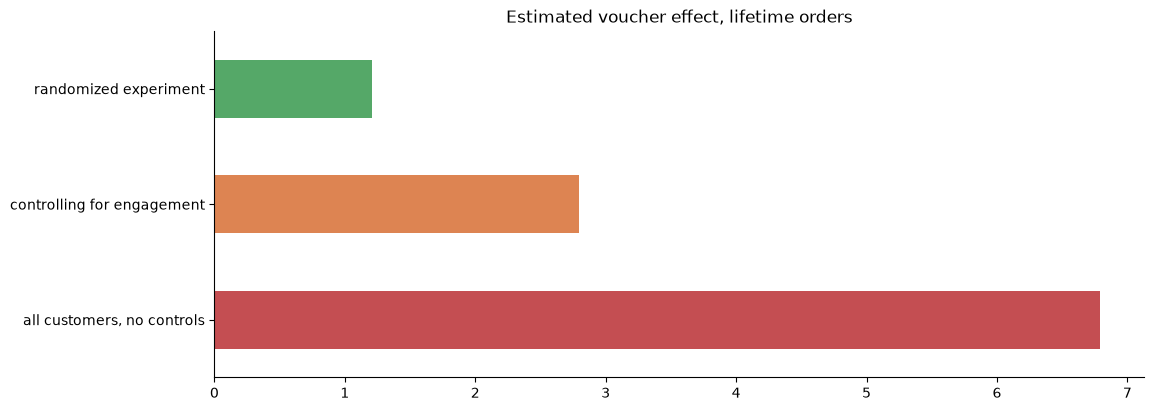

In [10]:
experiment = pd.read_csv("voucher_experiment.csv")
randomized = smf.ols("lifetime_orders ~ got_voucher", data=experiment).fit()
low, high = randomized.conf_int().loc["got_voucher"]
print(f"voucher effect in the randomized experiment: {randomized.params.got_voucher:.2f} orders (95% interval {low:.2f} to {high:.2f})")

estimates = pd.Series({"all customers, no controls": naive.params.got_voucher,
                       "controlling for engagement": controlled.params.got_voucher,
                       "randomized experiment": randomized.params.got_voucher})
ax = estimates.plot.barh(color=["#c44e52", "#dd8452", "#55a868"], title="Estimated voucher effect, lifetime orders")
plt.show()

## Results

- Orders are spread across many vendors: in every market except Saudi Arabia the HHI is under 400, far below the 1,500 threshold for a concentrated market, and the top 5 vendors take 11–35% of orders. Saudi Arabia, the smallest market with 97 vendors, is the exception: the top 5 take 63% of orders (HHI about 1,070). The same few chains lead in every market.
- Four vendor segments stand out: popular everyday vendors (64% of all orders), premium vendors with large baskets, promotion-driven vendors, and many small vendors with high delivery fees.
- The voucher regression overstates the effect several times over. The naive model says a first-visit voucher adds 6.8 lifetime orders; controlling for early engagement brings it to 2.8; a randomized experiment puts it at about 1.2 (95% interval 0.9 to 1.5). The vouchers went to customers who were going to order a lot anyway.
- The R² of 0.34 doesn't mean vouchers explain a third of customer behavior: it measures how much of the variation the model fits, including the part that comes from who got the voucher. A regression coefficient on a non-random treatment is a correlation, not an effect.

## Tools

Python, pandas, NumPy, scikit-learn (k-means), statsmodels, matplotlib